# Publisher KPI Forecasting & Target-Miss Alerts: walkthrough

**Question:** part-way through a month, which publishers will finish below their monthly commitment, by how much, and how confident can we be?

This notebook walks through the analysis behind the `kpi_forecast` package: the data, how targets are set, how the forecast works, how well the alerts held up over the past year, and what this month looks like. The heavy backtest (720 forecasts) is loaded from `reports/backtest_runs.csv`; rerun it with `python -m kpi_forecast.run`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from kpi_forecast.alerts import month_bounds
from kpi_forecast.backtest import accuracy_table, attach_targets, evaluate_alerts
from kpi_forecast.data import clean_daily, load_daily
from kpi_forecast.models import ets, seasonal_naive
from kpi_forecast.sql import monthly_kpis, monthly_targets

pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams['figure.figsize'] = (10, 4)
AS_OF = pd.Timestamp('2026-10-21')

## 1. Data and data quality

Daily user pageviews (bots and spiders excluded) for 10 Wikipedia language editions, each treated as one publisher. Before modelling, missing days are interpolated and one-day spikes are capped using a robust z-score. Every change is logged rather than made silently.

In [2]:
raw = load_daily(str(AS_OF.date()))
daily, quality_log = clean_daily(raw)
print(f'{len(raw):,} rows, {raw.publisher.nunique()} publishers, '
      f'{raw.date.min().date()} to {raw.date.max().date()}')
print(f'{len(quality_log)} days corrected ({len(quality_log) / len(raw):.2%} of all days)')
quality_log.groupby('publisher').size().rename('days corrected').to_frame().T

17,550 rows, 10 publishers, 2022-01-01 to 2026-10-21
76 days corrected (0.43% of all days)


publisher,Arabic,Dutch,English,French,German,Italian,Japanese,Polish,Portuguese,Spanish
days corrected,18,6,2,3,11,4,2,19,6,5


## 2. What the traffic looks like

Monthly totals, indexed to January 2022 = 100.

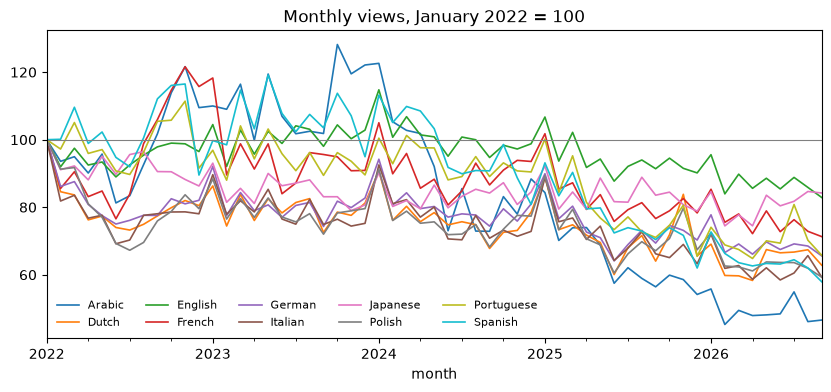

In [3]:
kpis = monthly_kpis(daily)
complete = kpis[kpis.is_complete]
indexed = complete.pivot(index='month', columns='publisher', values='views')
indexed = indexed / indexed.iloc[0] * 100
ax = indexed.plot(linewidth=1.2)
ax.axhline(100, color='grey', linewidth=0.8)
ax.set_title('Monthly views, January 2022 = 100')
ax.legend(ncol=5, fontsize=8, frameon=False)
plt.show()

Traffic is falling for almost every publisher. Year-on-year change over the last six complete months:

In [4]:
recent = complete[complete.month >= complete.month.max() - pd.DateOffset(months=5)]
recent.pivot(index='publisher', columns='month', values='yoy_change').rename(columns=lambda m: m.strftime('%b %Y')).map('{:.1%}'.format)

month,Apr 2026,May 2026,Jun 2026,Jul 2026,Aug 2026,Sep 2026
publisher,,,,,,
Arabic,-35.2%,-30.0%,-15.8%,-11.5%,-21.7%,-17.4%
Dutch,-18.7%,-3.0%,10.7%,-1.9%,-5.9%,-1.9%
English,-6.7%,-6.0%,-2.6%,-3.5%,-8.6%,-9.3%
French,-9.0%,-5.8%,-4.0%,-3.7%,-10.4%,-7.0%
German,-9.0%,-1.8%,5.2%,0.3%,-6.4%,-5.5%
Italian,-16.8%,-16.6%,-9.0%,-10.8%,-9.7%,-10.4%
Japanese,-6.2%,-5.7%,-1.5%,0.3%,-4.8%,0.8%
Polish,-13.5%,-7.3%,5.1%,-3.9%,-11.3%,-11.6%
Portuguese,-20.4%,-8.8%,-5.5%,4.8%,-3.4%,-7.4%


A strong weekly pattern is the other big feature, and the main thing a forecast for the rest of the month has to get right:

In [5]:
last_year = daily[daily.date > AS_OF - pd.Timedelta(days=365)].copy()
last_year['weekday'] = last_year.date.dt.day_name().str[:3]
weekly = last_year.groupby(['publisher', 'weekday']).views.mean().unstack()
weekly = weekly[['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']]
(weekly.div(weekly.mean(axis=1), axis=0) * 100).round(1)

weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
publisher,,,,,,,
Arabic,99.300,99.900,97.800,98.500,101.900,101.400,101.300
Dutch,98.700,96.400,96.300,96.000,100.400,101.900,110.200
English,102.500,99.100,98.000,98.000,97.800,99.500,105.000
French,101.300,98.100,97.600,96.400,97.400,100.100,109.100
German,102.000,97.400,95.800,96.400,98.100,99.900,110.300
Italian,99.500,98.600,96.600,96.400,95.600,101.700,111.500
Japanese,101.200,98.000,97.500,96.000,97.000,103.100,107.300
Polish,99.200,97.900,95.700,95.700,96.500,102.000,113.000
Portuguese,102.300,100.200,98.600,97.200,96.400,97.900,107.600


## 3. Setting monthly targets in SQL

With no real contracts, targets mimic how a commitment is usually negotiated: last year's month, moved by the publisher's trailing three-month year-on-year trend. The logic lives in `sql/targets.sql` and runs in DuckDB:

In [6]:
print((ROOT / 'sql' / 'targets.sql').read_text())

-- Monthly commitment per publisher.
--
--   target = same month last year x (1 + trailing 3-month YoY trend + stretch)
--
-- The trailing trend is the average year-on-year change of the three complete months
-- before the target month, so a commitment reflects where the publisher was heading
-- when it was set, not a flat repeat of last year. A target is only produced when
-- last year's month and all three trend months are complete.
-- Parameter ? = stretch on top of trend (0.0 = "keep your recent trajectory").
WITH monthly_raw AS (
    SELECT
        publisher,
        CAST(date_trunc('month', date) AS DATE) AS month,
        SUM(views)                              AS views,
        COUNT(*)                                AS days_reported
    FROM daily
    GROUP BY ALL
),
monthly AS (
    SELECT *, days_reported = day(last_day(month)) AS is_complete
    FROM monthly_raw
),
yoy AS (
    SELECT
        cur.publisher,
        cur.month,
        cur.views / prev.views - 1 AS yoy_change

In [7]:
targets = monthly_targets(daily, stretch=0.0)
targets[targets.month == AS_OF.replace(day=1)]

,publisher,month,target,trailing_yoy
42,Arabic,2026-10-01,"107,938,856.000",-0.169
85,Dutch,2026-10-01,"106,226,154.000",-0.032
128,English,2026-10-01,"6,640,384,024.000",-0.072
171,French,2026-10-01,"563,310,349.000",-0.070
214,German,2026-10-01,"719,888,465.000",-0.038
257,Italian,2026-10-01,"349,896,685.000",-0.103
300,Japanese,2026-10-01,"907,685,936.000",-0.012
343,Polish,2026-10-01,"181,714,181.000",-0.089
386,Portuguese,2026-10-01,"183,549,163.000",-0.020
429,Spanish,2026-10-01,"514,649,546.000",-0.152


**Why not simply 'same month last year'?** Because traffic is falling, a flat target would be missed almost every month, and an alert that always says 'miss' is right without being useful:

In [8]:
runs = pd.read_csv(ROOT / 'reports' / 'backtest_runs.csv', parse_dates=['month'])
months = runs[['publisher', 'month', 'actual_total']].drop_duplicates()
flat = months.merge(
    kpis[['publisher', 'month', 'views_last_year']], on=['publisher', 'month'])
trend = months.merge(targets, on=['publisher', 'month'])
print(f'Flat YoY target missed:      {(flat.actual_total < flat.views_last_year).sum()} of {len(flat)} publisher-months')
print(f'Trend-adjusted target missed: {(trend.actual_total < trend.target).sum()} of {len(trend)} publisher-months')

Flat YoY target missed:      111 of 120 publisher-months
Trend-adjusted target missed: 61 of 120 publisher-months


## 4. Forecasting the rest of the month

Two models: a **seasonal-naive** baseline (each day equals the same weekday last week) and **Holt-Winters ETS** with a damped trend and weekly seasonality, fitted on the log scale. Here is English Wikipedia as of 21 October:

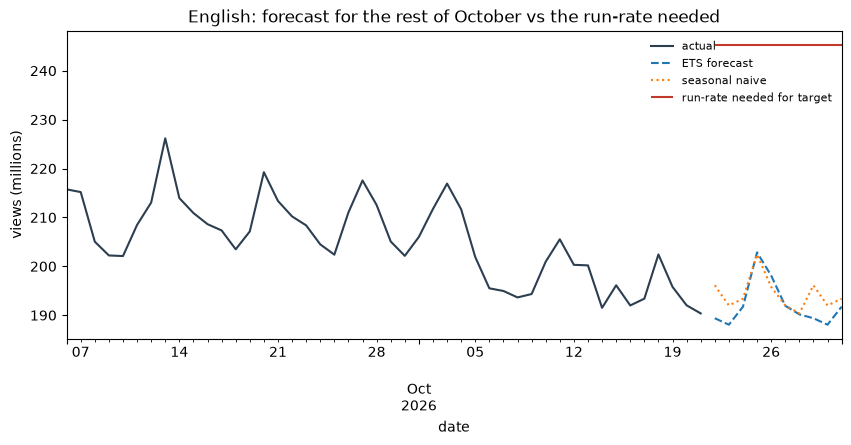

In [9]:
series = daily[daily.publisher == 'English'].set_index('date').views.sort_index()
start, end = month_bounds(AS_OF)
horizon = (end - AS_OF).days
history = series[:AS_OF]
f_ets, f_naive = ets(history, horizon), seasonal_naive(history, horizon)

window = history[AS_OF - pd.Timedelta(days=45):]
ax = (window / 1e6).plot(color='#2c3e50', label='actual')
(f_ets / 1e6).plot(ax=ax, linestyle='--', label='ETS forecast')
(f_naive / 1e6).plot(ax=ax, linestyle=':', label='seasonal naive')
target = targets.set_index(['publisher', 'month']).loc[('English', start), 'target']
needed = (target - series[start:AS_OF].sum()) / horizon
ax.hlines(needed / 1e6, f_ets.index[0], f_ets.index[-1], color='#c0392b', label='run-rate needed for target')
ax.set_ylabel('views (millions)')
ax.set_title('English: forecast for the rest of October vs the run-rate needed')
ax.legend(frameon=False, fontsize=8)
plt.show()

## 5. Backtest: how good were the forecasts and the alerts?

Each of the last 12 months was replayed as if live, from the 7th, 14th and 21st, using only data available on that day. First, forecast error on the rest-of-month total:

In [10]:
backtest = attach_targets(runs, targets)
accuracy_table(backtest).pivot(index='check_day', columns='model', values='remaining_total_mape').map('{:.2%}'.format)

model,ets,seasonal_naive
check_day,,
7,3.48%,3.62%
14,3.48%,3.36%
21,3.75%,3.91%


ETS is only slightly better than the baseline: for a monthly total, the weekly pattern does most of the work. The pipeline picks whichever model had the lower error for the day it runs.

Next, the alerts. Each publisher is projected to month end with a 90% range built from past errors (calibrated leave-one-month-out, so a month never judges its own alert), then labelled `MISS LIKELY`, `AT RISK` or `ON TRACK`:

In [11]:
scored, summary = evaluate_alerts(backtest, 'ets')
summary.set_index('check_day')[['actual_misses', 'alert_precision', 'alert_recall', 'status_accuracy', 'miss_likely_precision', 'range_coverage']]

,actual_misses,alert_precision,alert_recall,status_accuracy,miss_likely_precision,range_coverage
check_day,,,,,,
7,61.000,0.895,0.836,0.867,1.000,0.883
14,61.000,0.931,0.885,0.908,1.000,0.892
21,61.000,0.950,0.934,0.942,1.000,0.875


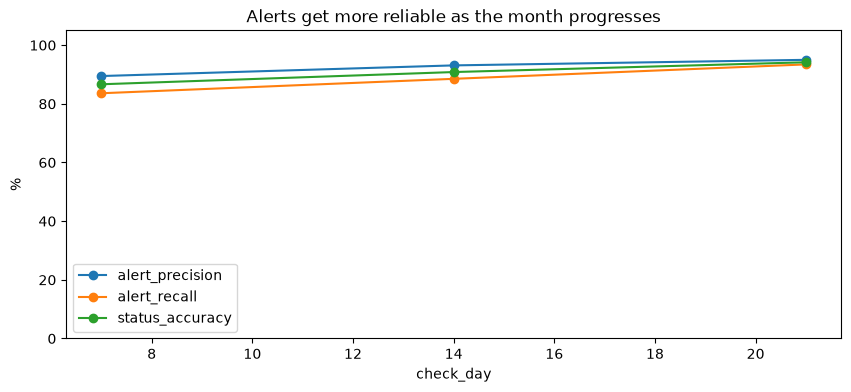

In [12]:
ax = summary.set_index('check_day')[['alert_precision', 'alert_recall', 'status_accuracy']].mul(100).plot(marker='o')
ax.set_ylim(0, 105)
ax.set_ylabel('%')
ax.set_title('Alerts get more reliable as the month progresses')
plt.show()

By the 7th the system catches about 84% of the misses that will happen, and by the 21st about 95% of its alerts are right. Every `MISS LIKELY` alert in the backtest was a real miss. The 90% range covered 87.5% to 89% of outcomes, so it is slightly narrow.

## 6. This month: October 2026, as of 21 October

In [13]:
alerts = pd.read_csv(ROOT / 'reports' / 'alerts.csv')
view = alerts[['publisher', 'status', 'attainment', 'attainment_low', 'attainment_high', 'uplift_needed']].copy()
for col in ['attainment', 'attainment_low', 'attainment_high', 'uplift_needed']:
    view[col] = view[col].map('{:.1%}'.format)
view

,publisher,status,attainment,attainment_low,attainment_high,uplift_needed
0,Arabic,MISS LIKELY,85.1%,82.7%,87.3%,55.3%
1,Dutch,MISS LIKELY,88.8%,86.3%,91.1%,40.1%
2,Spanish,MISS LIKELY,88.8%,86.2%,91.2%,39.2%
3,Portuguese,MISS LIKELY,89.2%,86.7%,91.5%,38.9%
4,Polish,MISS LIKELY,89.8%,87.2%,92.1%,35.9%
5,German,MISS LIKELY,90.3%,87.7%,92.7%,33.5%
6,English,MISS LIKELY,92.0%,89.4%,94.4%,27.7%
7,French,MISS LIKELY,92.7%,90.1%,95.1%,25.2%
8,Japanese,MISS LIKELY,93.2%,90.4%,95.6%,23.0%
9,Italian,MISS LIKELY,95.7%,93.0%,98.1%,14.6%


In [14]:
for name in ['English', 'Arabic']:
    s = daily[daily.publisher == name].set_index('date').views
    this_year = s['2026-10-01':'2026-10-21'].mean()
    last_year = s['2025-10-01':'2025-10-21'].mean()
    trend = targets.set_index(['publisher', 'month']).loc[(name, pd.Timestamp('2026-10-01')), 'trailing_yoy']
    print(f'{name}: Oct 1-21 average {this_year / 1e6:.1f}M vs {last_year / 1e6:.1f}M last year '
          f'({this_year / last_year - 1:+.1%}), trend going in {trend:+.1%}')

English: Oct 1-21 average 199.4M vs 231.6M last year (-13.9%), trend going in -7.2%
Arabic: Oct 1-21 average 3.0M vs 4.1M last year (-27.6%), trend going in -16.9%


**Reading this month:** every publisher is projected to miss. When all accounts move together the cause is usually shared (a measurement change, a platform-level traffic shift, a calendar effect) rather than ten separate partner problems, so the first step is to look for that common cause before contacting individual publishers.

## 7. Limits and next steps

- The targets are illustrative; real commitments would come from contracts.
- One KPI per publisher. A real view would add revenue, fill rate and engagement.
- Next: a scheduled daily run that posts status changes to Slack, holiday regressors, and hierarchical forecasts so the portfolio total and publishers stay consistent.